In [6]:
!pip install pyspark==3.5.9 openpyxl
import pandas as pd
from pathlib import Path

input_file = "/content/Online Retail.xlsx"
output_file = "/content/online_retail.csv"

df_excel = pd.read_excel(input_file, engine="openpyxl")

print("Jumlah baris awal:", len(df_excel))
print("Kolom:", df_excel.columns.tolist())
print("Nilai kosong per kolom:")
print(df_excel.isna().sum())
print("Jumlah baris duplikat:", df_excel.duplicated().sum())

df_excel.to_csv(output_file, index=False)
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from time import perf_counter

spark = (
    SparkSession.builder
    .appName("EksplorasiMahadataRetail")
    .master("local[*]")
    .getOrCreate()
)

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(output_file)
)

df.printSchema()
df.show(5, truncate=False)

print("Jumlah baris Spark:", df.count())
df_clean = (
    df
    .withColumn(
        "InvoiceDate",
        F.to_timestamp("InvoiceDate", "M/d/yyyy H:mm")
    )
    .withColumn("Quantity", F.col("Quantity").cast("long"))
    .withColumn("UnitPrice", F.col("UnitPrice").cast("double"))
    .filter(
        F.col("InvoiceNo").isNotNull()
        & (~F.upper(F.trim(F.col("InvoiceNo"))).startswith("C"))
        & F.col("Quantity").isNotNull()
        & F.col("UnitPrice").isNotNull()
        & (F.col("Quantity") > 0)
        & (F.col("UnitPrice") > 0)
        & F.col("Description").isNotNull()
        & F.col("InvoiceDate").isNotNull()
    )
    .dropDuplicates()
    .withColumn(
        "SalesValue",
        F.col("Quantity") * F.col("UnitPrice")
    )
    .cache()
)

print("Baris setelah pembersihan:", df_clean.count())
# Ringkasan keseluruhan
df_clean.agg(
    F.count("*").alias("jumlah_baris"),
    F.sum("Quantity").alias("total_unit"),
    F.sum("SalesValue").alias("total_penjualan_gbp"),
    F.countDistinct("InvoiceNo").alias("jumlah_faktur"),
    F.countDistinct("CustomerID").alias("jumlah_pelanggan")
).show(truncate=False)

# Sepuluh produk berdasarkan nilai penjualan
top_products = (
    df_clean
    .groupBy("StockCode", "Description")
    .agg(
        F.sum("Quantity").alias("total_unit"),
        F.sum("SalesValue").alias("total_penjualan_gbp")
    )
    .orderBy(F.desc("total_penjualan_gbp"))
    .limit(10)
)

top_products.show(truncate=False)
top_products.coalesce(1).write.mode("overwrite").option(
    "header", True
).csv("/content/hasil_produk_teratas")
benchmark = []

for n in [1, 2, 4, 8]:
    df_part = df_clean.repartition(n)

    start = perf_counter()

    result = (
        df_part
        .groupBy("Country")
        .agg(
            F.sum("SalesValue").alias("total_penjualan"),
            F.count("*").alias("jumlah_transaksi")
        )
    )

    # Action memaksa Spark menghitung hasil
    result.collect()

    elapsed = perf_counter() - start

    benchmark.append({
        "partisi": n,
        "waktu_detik": round(elapsed, 3)
    })

benchmark_df = pd.DataFrame(benchmark)
print(benchmark_df)

benchmark_df.to_csv(
    "/content/benchmark_partisi.csv", index=False
)


Jumlah baris awal: 541909
Kolom: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Nilai kosong per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Jumlah baris duplikat: 5268
root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- CustomerID: double (nullable = true)
 |-- Country: string (nullable = true)

+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+------------

1. SparkSession berhasil diinisialisasi!
2. DataFrame PySpark 'clean_df' berhasil dibuat!
   Jumlah total baris data: 541909

=== 3. MEMULAI BENCHMARK PARTISI ===
Sedang menguji 1 partisi...
Sedang menguji 2 partisi...
Sedang menguji 4 partisi...
Sedang menguji 8 partisi...

=== TABEL RINGKASAN HASIL BENCHMARK ===


,partisi,rata_rata_detik,tercepat_detik,terlama_detik
0,1,2.387,1.686,3.707
1,2,3.104,2.173,3.999
2,4,2.444,2.170,2.930
3,8,3.882,2.371,5.472



Hasil pengujian dan ringkasan berhasil disimpan ke file CSV.


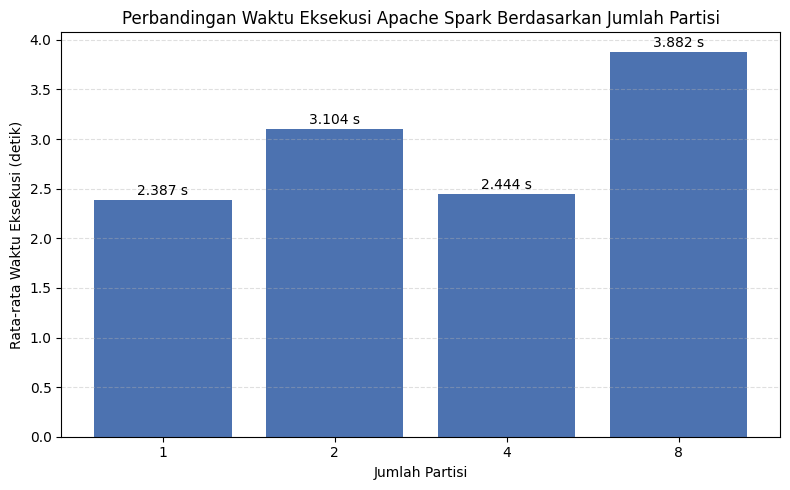

In [10]:

import os
import time
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from IPython.display import display

# 1. Inisialisasi SparkSession
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("Eksperimen_Mahadata_Retail") \
    .getOrCreate()

print("1. SparkSession berhasil diinisialisasi!")

# 2. Siapkan file CSV dan buat clean_df di PySpark
excel_file = "/content/Online Retail.xlsx"
csv_file = "/content/online_retail.csv"

# Jika file CSV belum ada, konversi dari Excel
if not os.path.exists(csv_file):
    if os.path.exists(excel_file):
        print("Membaca file Excel ke Pandas...")
        df_pd = pd.read_excel(excel_file)
        df_pd.to_csv(csv_file, index=False)
        print("Berhasil mengonversi Excel ke CSV.")
    else:
        raise FileNotFoundError("File Online Retail.xlsx tidak ditemukan!")

# Membaca CSV ke PySpark DataFrame
clean_df = spark.read.csv(csv_file, header=True, inferSchema=True)

# Tambahkan kolom SalesValue (Quantity * UnitPrice)
clean_df = clean_df.withColumn("SalesValue", F.col("Quantity") * F.col("UnitPrice"))

print("2. DataFrame PySpark 'clean_df' berhasil dibuat!")
print(f"   Jumlah total baris data: {clean_df.count()}\n")

# 3. Jalankan Pengujian Benchmark (1, 2, 4, 8 Partisi)
daftar_partisi = [1, 2, 4, 8]
jumlah_percobaan = 3
hasil_uji = []

print("=== 3. MEMULAI BENCHMARK PARTISI ===")
for n in daftar_partisi:
    print(f"Sedang menguji {n} partisi...")
    df_part = clean_df.repartition(n)

    # Pemanasan awal (warm-up)
    df_part.groupBy("Country").agg(F.sum("SalesValue").alias("total_penjualan")).collect()

    # 3 kali percobaan
    for percobaan in range(1, jumlah_percobaan + 1):
        mulai = perf_counter()
        df_part.groupBy("Country").agg(F.sum("SalesValue").alias("total_penjualan")).collect()
        durasi = perf_counter() - mulai

        hasil_uji.append({
            "partisi": n,
            "percobaan": percobaan,
            "waktu_detik": round(durasi, 3)
        })

# Simpan ke DataFrame Pandas
hasil_df = pd.DataFrame(hasil_uji)

# 4. Buat Tabel Ringkasan
ringkasan = (
    hasil_df.groupby("partisi")["waktu_detik"]
    .agg(["mean", "min", "max"])
    .reset_index()
)
ringkasan.columns = ["partisi", "rata_rata_detik", "tercepat_detik", "terlama_detik"]
ringkasan = ringkasan.round(3)

print("\n=== TABEL RINGKASAN HASIL BENCHMARK ===")
display(ringkasan)

# 5. Simpan Hasil Pengujian ke File CSV
hasil_df.to_csv("/content/hasil_pengujian_partisi.csv", index=False)
ringkasan.to_csv("/content/ringkasan_benchmark.csv", index=False)
print("\nHasil pengujian dan ringkasan berhasil disimpan ke file CSV.")

# 6. Tampilkan Grafik Perbandingan Waktu Eksekusi
plt.figure(figsize=(8, 5))
bars = plt.bar(ringkasan["partisi"].astype(str), ringkasan["rata_rata_detik"], color='#4C72B0')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.3f} s", ha='center', va='bottom')

plt.xlabel("Jumlah Partisi")
plt.ylabel("Rata-rata Waktu Eksekusi (detik)")
plt.title("Perbandingan Waktu Eksekusi Apache Spark Berdasarkan Jumlah Partisi")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()